# Life-stage polities: how each stage is found (whole database)
Share of each stage (%) found by each Wikidata field and method, over every individual with a birth and a death year. Read from the parquets of `01_life_stage_polities_export.py` (one per 1,000,000 individuals); the method is explored on a sample in `01_life_stage_polities.ipynb`. A stage is found by Wikipedia Url when at least one of its locations matched a polity's Wikipedia article, else by center coordinates (the location's Wikidata point, P625, inside a polity's borders). The total, not found included, is 100%; the three largest shares of each stage (not found aside) are in bold; a blank cell is no individual.

In [1]:
import sys
from pathlib import Path

import polars as pl

sys.path.insert(0, '../notebooks_analysis')
from style import show_table

EXPORT = Path('../../data/enriched_parquets/individual_life_stage_polities')
STAGES = ['early', 'active', 'late']
FIELDS = ['birthplace', 'educated at', 'residence', 'citizenship', 'work location', 'employer', 'position held', 'deathplace', 'not found']
METHODS = {'URL': 'Wikipedia Url', 'coordinates': 'Center coordinates', '—': '—'}

In [2]:
stages = pl.read_parquet(EXPORT / 'batch_*.parquet', columns=['qid', 'stage', 'wikidata_field', 'method'])
print(f"{stages['qid'].n_unique():,} individuals, {stages.height:,} stages")

3,905,024 individuals, 10,302,309 stages


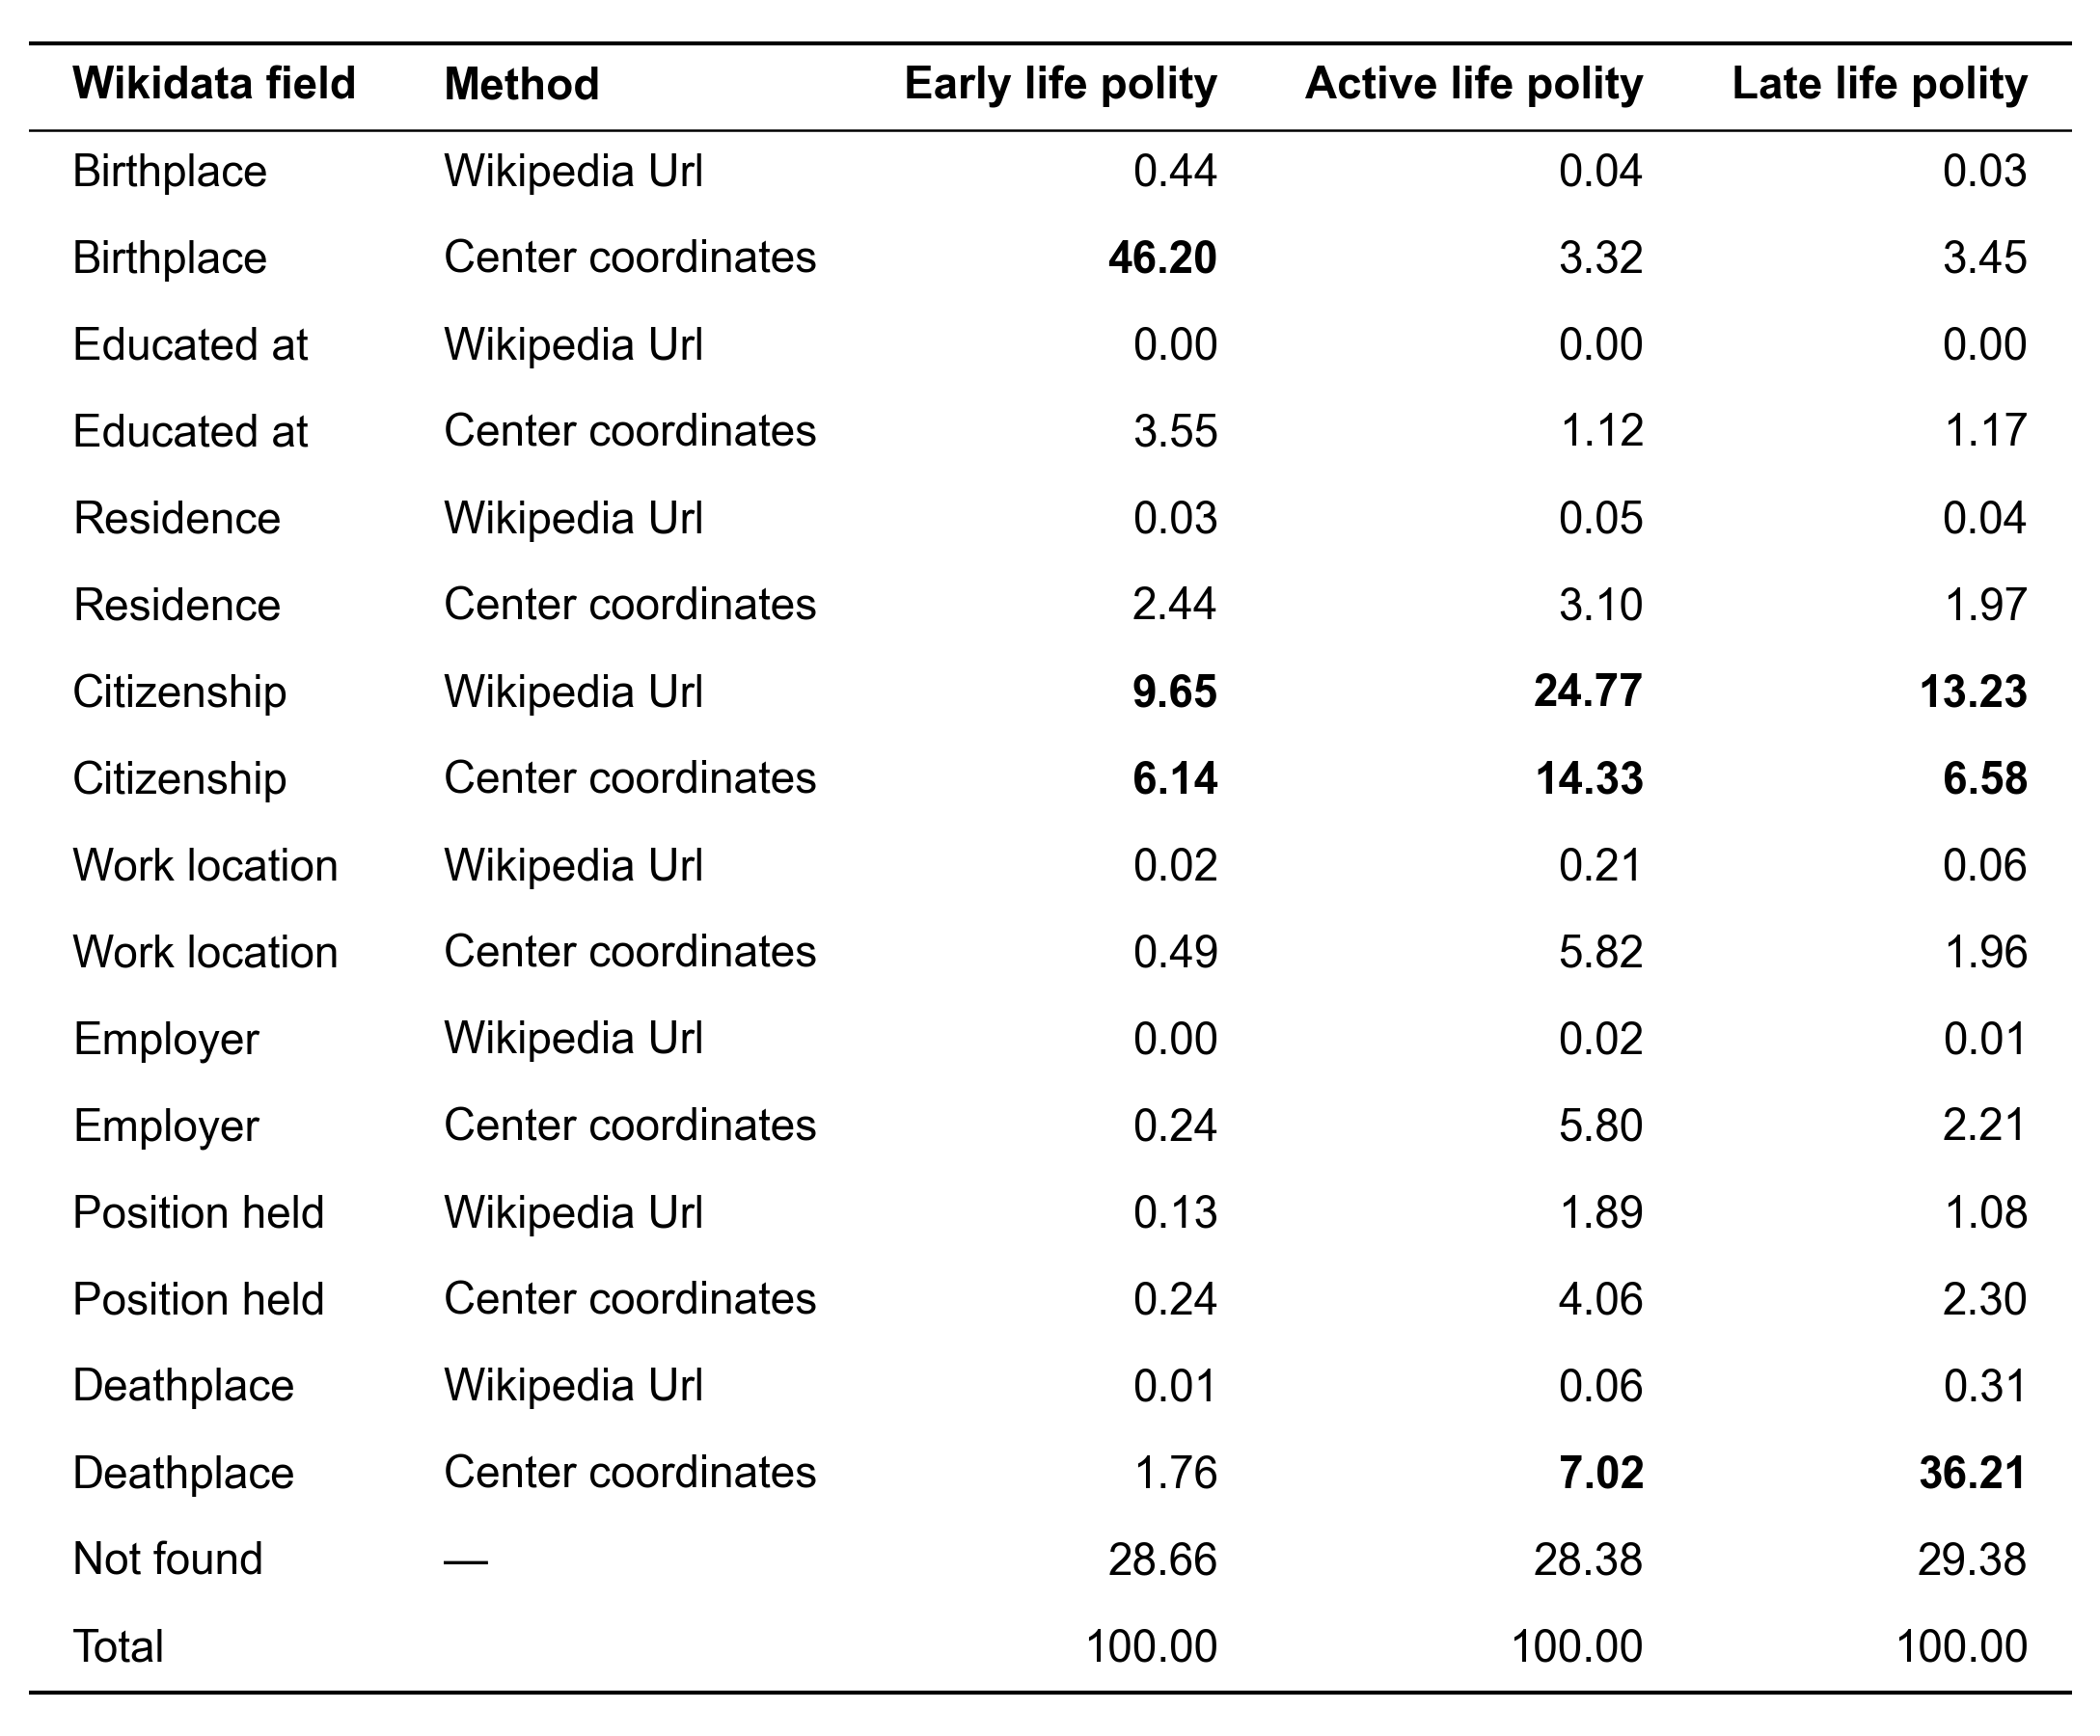

In [3]:
found_by = (
    stages.with_columns(
        field=pl.col('wikidata_field').fill_null('not found'),
        method=pl.col('method').fill_null('—'),
        individuals=pl.len().over('stage'),
    )
    .group_by('stage', 'field', 'method').agg(share=100 * pl.len() / pl.col('individuals').first())
    .pivot(on='stage', index=['field', 'method'], values='share')
    .with_columns(pl.col(STAGES).fill_null(0.0))
    .sort(pl.col('field').replace_strict({name: rank for rank, name in enumerate(FIELDS)}), pl.col('method').replace_strict({name: rank for rank, name in enumerate(METHODS)}))
    .select('field', 'method', *STAGES)
)
total = found_by.select(pl.lit('total').alias('field'), pl.lit('').alias('method'), pl.col(STAGES).sum())
columns = {stage: f'{stage.capitalize()} life polity' for stage in STAGES}
ranked = found_by.with_columns(pl.when(pl.col('field') == 'not found').then(None).otherwise(pl.col(stage)).alias(stage) for stage in STAGES)
top_three = {(row, columns[stage]) for stage in STAGES for row in ranked[stage].arg_sort(descending=True, nulls_last=True)[:3].to_list()}

table = pl.concat([found_by, total]).with_columns(
    pl.col('field').str.slice(0, 1).str.to_uppercase() + pl.col('field').str.slice(1),
    pl.col('method').replace(METHODS),
    pl.col(STAGES).map_elements(lambda share: f'{share:.2f}' if share else '', return_dtype=pl.String),
)
show_table(table.rename({'field': 'Wikidata field', 'method': 'Method', **columns}), bold_cells=top_three)